In [31]:
%pip install pandas scipy matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [32]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import differential_evolution

In [33]:
N_TRIALS = 300
# new pairs of bandit trials
BLOCK_STARTS = {0, 100, 200}
DATA_FILE = "dataset_students.csv"

# param names and bounds per model
MODELS = {
    "M1": (["alpha", "beta"], [(0, 1), (0.001, 30)]),
    "M2": (["alpha_pos", "alpha_neg", "beta"], [(0, 1), (0, 1), (0.001, 30)]),
    "M3": (["alpha", "beta", "q0"], [(0, 1), (0.001, 30), (0, 1)]),
    "M4": (["alpha_pos", "alpha_neg", "beta", "q0"], [(0, 1), (0, 1), (0.001, 30), (0, 1)]),
}

In [34]:
df = pd.read_csv(DATA_FILE)
df["choice"] = df["R"].map({"left": 0, "right": 1})
assert len(df) == 12000, f"expected 40 x 300 rows, got {len(df)}"


def subject_data(df, s):
    #retursn choices rewards and group for subject s
    d = df[df["subjects"] == s]
    return d["choice"].to_numpy(int), d["reward"].to_numpy(float), d["group"].iloc[0]

In [35]:
def log_lik(alpha_pos, alpha_neg, beta, q0, choices, rewards):
    # log likeligood of a subjects choice under delta rule + softmax
    Q = np.full(2, q0, dtype=float)
    ll = 0.0
    for t in range(N_TRIALS):
        if t in BLOCK_STARTS:
            # resets inital value for new bandits
            Q[:] = q0
            
        c = choices[t]

        #softmax
        p_right = 1.0 / (1.0 + np.exp(-beta * (Q[1] - Q[0])))
        p = p_right if c == 1 else 1.0 - p_right
        ll += np.log(max(p, 1e-12))

        #prediction error
        pe = rewards[t] - Q[c]
        Q[c] += (alpha_pos if pe > 0 else alpha_neg) * pe
    return ll

In [36]:
def neg_ll(params, model, choices, rewards):
    #negative log likely for the optimiser
    
    if model == "M1":
        alpha, beta = params
        full = (alpha, alpha, beta, 0.5)
    elif model == "M2":
        a_pos, a_neg, beta = params
        full = (a_pos, a_neg, beta, 0.5)
    elif model == "M3":
        alpha, beta, q0 = params
        full = (alpha, alpha, beta, q0)
    elif model == "M4":
        full = tuple(params)
    else:
        raise ValueError(f"unknown model {model}")
    return -log_lik(*full, choices, rewards)

In [37]:
def fit_model(model, choices, rewards, seeds=(0, 1, 2)):
    #fits one model to one subject
    names, bounds = MODELS[model]
    runs = [differential_evolution(neg_ll, bounds, args=(model, choices, rewards), seed=s)
            for s in seeds]
    best = min(runs, key=lambda r: r.fun)

    ll = -best.fun
    fit = dict(zip(names, best.x))
    fit["loglik"] = ll
    fit["bic"] = len(names) * np.log(N_TRIALS) - 2 * ll
    return fit

In [38]:
def fit_all(df, model):
    #fits one model to everysubject
    path = f"results_{model}.csv"
    if os.path.exists(path):
        print(f"loading cached {path}")
        return pd.read_csv(path)

    rows = []
    for s in np.sort(df["subjects"].unique()):
        choices, rewards, group = subject_data(df, s)
        t0 = time.time()
        fit = fit_model(model, choices, rewards)
        rows.append({"subject": s, "group": group, **fit})
        print(f"{model} subj {s:2d} ({group}): lnL = {fit['loglik']:.2f}  [{time.time() - t0:.1f}s]")

    res = pd.DataFrame(rows)
    res.to_csv(path, index=False)
    return res

In [39]:
results = {m: fit_all(df, m) for m in MODELS}

#check all fits should beat random choice (300 * ln 0.5 = -207.94)
for m, res in results.items():
    print(m, "worst lnL:", round(res["loglik"].min(), 2))

# nested model check, bigger models cant fit worse with some tollerance
for big, small in [("M2", "M1"), ("M3", "M1"), ("M4", "M2"), ("M4", "M3")]:
    worse = results[big]["loglik"] < results[small]["loglik"] - 1e-3
    failed = results[big].loc[worse, "subject"].tolist()
    print(f"{big} >= {small}:", "OK" if not failed else f"FAILED for {failed}")

loading cached results_M1.csv
loading cached results_M2.csv
loading cached results_M3.csv
loading cached results_M4.csv
M1 worst lnL: -202.27
M2 worst lnL: -201.76
M3 worst lnL: -201.98
M4 worst lnL: -201.76
M2 >= M1: OK
M3 >= M1: OK
M4 >= M2: OK
M4 >= M3: OK


In [40]:
model_names = list(MODELS)
bic = pd.DataFrame({m: results[m]["bic"] for m in model_names})
bic["group"] = results["M1"]["group"]
bic["winner"] = bic[model_names].idxmin(axis=1)

#BIC talbe + best model per subject 
print("summed BIC per group (lower = better)")
print(bic.groupby("group")[model_names].sum().round(1))
print("\nwinning model per participant")
print(pd.crosstab(bic["group"], bic["winner"]))

summed BIC per group (lower = better)
               M1      M2      M3      M4
group                                    
depressed  5801.4  5848.6  5836.2  5892.0
healthy    3852.0  3390.5  3356.5  3448.9

winning model per participant
winner     M1  M2  M3  M4
group                    
depressed  15   2   1   2
healthy     5   4  11   0


In [41]:
P_LEFT = np.repeat([0.8, 0.7, 0.6], 100)


#Simulates one subject with the same model as log_lik
def simulate(alpha_pos, alpha_neg, beta, q0, rng):
    choices = np.zeros(N_TRIALS, dtype=int)
    rewards = np.zeros(N_TRIALS)
    Q = np.full(2, q0, dtype=float)

    for t in range(N_TRIALS):
        if t in BLOCK_STARTS:
            Q[:] = q0

        p_right = 1 / (1 + np.exp(-beta * (Q[1] - Q[0])))
        choice = int(rng.random() < p_right)

        p_reward = P_LEFT[t] if choice == 0 else 1 - P_LEFT[t]
        reward = float(rng.random() < p_reward)

        pe = reward - Q[choice]
        alpha = alpha_pos if pe > 0 else alpha_neg
        Q[choice] += alpha * pe

        choices[t] = choice
        rewards[t] = reward

    return choices, rewards


generating = {
    "M2 (asymmetric, Q0 = 0.5)": {
        "alpha_pos": 0.23, "alpha_neg": 0.07, "beta": 10, "q0": 0.5
    },
    "M3 (symmetric, Q0 = 0.05)": {
        "alpha_pos": 0.13, "alpha_neg": 0.13, "beta": 10, "q0": 0.05
    }
}

N_SIM = 20
rng = np.random.default_rng(1)

rows = []

for label, params in generating.items():
    for i in range(N_SIM):
        print(f"{label}: sim {i + 1}/{N_SIM}")

        choices, rewards = simulate(**params, rng=rng)
        fits = {m: fit_model(m, choices, rewards) for m in ["M1", "M2", "M3"]}

        rows.append({
            "true model": label,
            "BIC winner": min(fits, key=lambda m: fits[m]["bic"]),
            "fitted M2 gap": fits["M2"]["alpha_pos"] - fits["M2"]["alpha_neg"],
            "fitted M3 q0": fits["M3"]["q0"]
        })

recovery = pd.DataFrame(rows)

print(pd.crosstab(recovery["true model"], recovery["BIC winner"]))

print(
    recovery.groupby("true model")[["fitted M2 gap", "fitted M3 q0"]]
    .median()
    .round(3)
)

M2 (asymmetric, Q0 = 0.5): sim 1/20
M2 (asymmetric, Q0 = 0.5): sim 2/20
M2 (asymmetric, Q0 = 0.5): sim 3/20
M2 (asymmetric, Q0 = 0.5): sim 4/20
M2 (asymmetric, Q0 = 0.5): sim 5/20
M2 (asymmetric, Q0 = 0.5): sim 6/20
M2 (asymmetric, Q0 = 0.5): sim 7/20
M2 (asymmetric, Q0 = 0.5): sim 8/20
M2 (asymmetric, Q0 = 0.5): sim 9/20
M2 (asymmetric, Q0 = 0.5): sim 10/20
M2 (asymmetric, Q0 = 0.5): sim 11/20
M2 (asymmetric, Q0 = 0.5): sim 12/20
M2 (asymmetric, Q0 = 0.5): sim 13/20
M2 (asymmetric, Q0 = 0.5): sim 14/20
M2 (asymmetric, Q0 = 0.5): sim 15/20
M2 (asymmetric, Q0 = 0.5): sim 16/20
M2 (asymmetric, Q0 = 0.5): sim 17/20
M2 (asymmetric, Q0 = 0.5): sim 18/20
M2 (asymmetric, Q0 = 0.5): sim 19/20
M2 (asymmetric, Q0 = 0.5): sim 20/20
M3 (symmetric, Q0 = 0.05): sim 1/20
M3 (symmetric, Q0 = 0.05): sim 2/20
M3 (symmetric, Q0 = 0.05): sim 3/20
M3 (symmetric, Q0 = 0.05): sim 4/20
M3 (symmetric, Q0 = 0.05): sim 5/20
M3 (symmetric, Q0 = 0.05): sim 6/20
M3 (symmetric, Q0 = 0.05): sim 7/20
M3 (symmetric, Q0

In [42]:
# median IQR as a string
def describe(x):
    q25, q50, q75 = np.percentile(x, [25, 50, 75])
    return f"{q50:.3f} [{q25:.3f}, {q75:.3f}]"

# format p-value
def fmt_p(p):
    return "p<0.001" if p < 0.001 else f"p={p:.4f}"

# healthy vs MDD; Mann-Whitney U + rank-biserial r returns p
def mwu_groups(res, param):
    h = res.loc[res["group"] == "healthy", param]
    d = res.loc[res["group"] == "depressed", param]

    u, p = stats.mannwhitneyu(h, d)
    r = 2 * u / (len(h) * len(d)) - 1

    print(
        f"{param:9} healthy {describe(h)}  "
        f"MDD {describe(d)}  U={u:.0f}  "
        f"{fmt_p(p)}  r={r:.2f}"
    )
    return p

# alpha_pos vs alpha_neg within a group 
def wilcoxon_alphas(res, group):
    sub = res[res["group"] == group]
    diff = (sub["alpha_pos"] - sub["alpha_neg"]).to_numpy()
    diff = diff[diff != 0]

    w, p = stats.wilcoxon(diff)
    ranks = stats.rankdata(np.abs(diff))
    r = (
        ranks[diff > 0].sum() - ranks[diff < 0].sum()
    ) / ranks.sum()

    print(
        f"{group:9} alpha_pos - alpha_neg "
        f"{describe(diff)}  W={w:.0f}  "
        f"{fmt_p(p)}  r={r:.2f}"
    )
    return p


results["M2"]["gap"] = (
    results["M2"]["alpha_pos"] - results["M2"]["alpha_neg"]
)

print("Section A: learning rates")

pvals = {
    "alpha (M1)": mwu_groups(results["M1"], "alpha"),
    "alpha_pos (M2)": mwu_groups(results["M2"], "alpha_pos"),
    "alpha_neg (M2)": mwu_groups(results["M2"], "alpha_neg"),
    "gap (M2)": mwu_groups(results["M2"], "gap"),
    "healthy within": wilcoxon_alphas(results["M2"], "healthy"),
    "MDD within": wilcoxon_alphas(results["M2"], "depressed")
}

print("\nSection B: inverse temperature")
pvals["beta (M1)"] = mwu_groups(results["M1"], "beta")

m = len(pvals)
order = sorted(pvals, key=pvals.get)
thresholds = 0.05 / (m - np.arange(m))

passed = np.cumprod([
    pvals[name] < threshold
    for name, threshold in zip(order, thresholds)
]).astype(bool)

print(f"\nHolm correction over {m} tests:")

for name, threshold, ok in zip(order, thresholds, passed):
    status = "pass" if ok else "fail"
    print(
        f"{name:15} {fmt_p(pvals[name]):9} "
        f"threshold={threshold:.4f}  {status}"
    )

Section A: learning rates
alpha     healthy 0.134 [0.045, 0.175]  MDD 0.172 [0.083, 0.297]  U=128  p=0.0531  r=-0.36
alpha_pos healthy 0.234 [0.162, 0.355]  MDD 0.169 [0.049, 0.323]  U=248  p=0.1988  r=0.24
alpha_neg healthy 0.074 [0.047, 0.096]  MDD 0.147 [0.073, 0.290]  U=101  p=0.0077  r=-0.49
gap       healthy 0.148 [0.079, 0.280]  MDD 0.022 [-0.077, 0.072]  U=321  p=0.0011  r=0.60
healthy   alpha_pos - alpha_neg 0.148 [0.079, 0.280]  W=0  p<0.001  r=1.00
depressed alpha_pos - alpha_neg 0.022 [-0.077, 0.072]  W=98  p=0.8124  r=0.07

Section B: inverse temperature
beta      healthy 10.842 [6.813, 22.735]  MDD 4.545 [2.819, 7.075]  U=338  p<0.001  r=0.69

Holm correction over 7 tests:
healthy within  p<0.001   threshold=0.0071  pass
beta (M1)       p<0.001   threshold=0.0083  pass
gap (M2)        p=0.0011  threshold=0.0100  pass
alpha_neg (M2)  p=0.0077  threshold=0.0125  pass
alpha (M1)      p=0.0531  threshold=0.0167  fail
alpha_pos (M2)  p=0.1988  threshold=0.0250  fail
MDD within

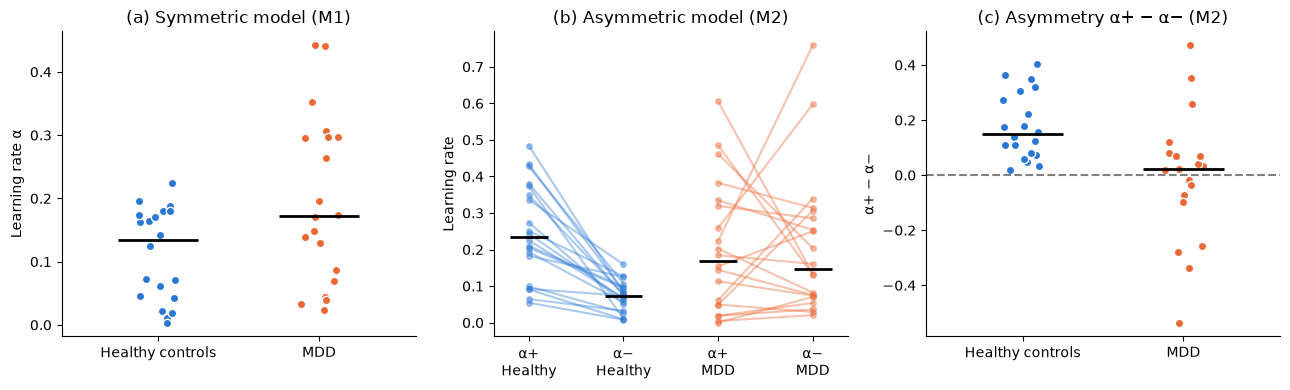

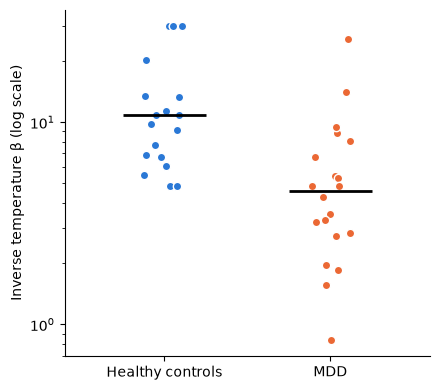

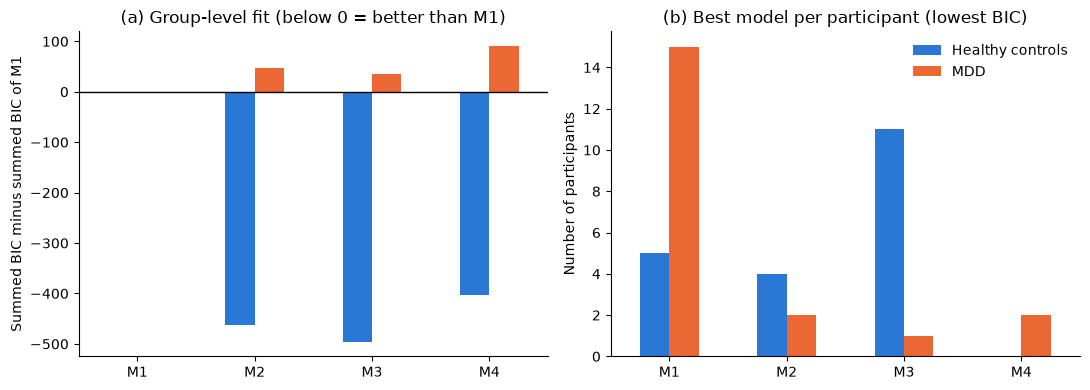

In [43]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

GROUPS = ["healthy", "depressed"]
LABELS = {"healthy": "Healthy controls", "depressed": "MDD"}
COLORS = {"healthy": "#2a78d6", "depressed": "#eb6834"}

#Dot per subject (fixed jitter) + median bar per group
def strip_plot(ax, res, param, ylabel, title="", log=False, ref=None):
    jitter_rng = np.random.default_rng(0)
    for i, g in enumerate(GROUPS):
        y = res.loc[res["group"] == g, param]
        x = i + jitter_rng.uniform(-0.12, 0.12, len(y))
        ax.scatter(x, y, color=COLORS[g], edgecolor="white")
        ax.hlines(y.median(), i - 0.25, i + 0.25, color="black", linewidth=2)
    if ref is not None:
        ax.axhline(ref, color="grey", linestyle="--")
    ax.set_xticks([0, 1], [LABELS[g] for g in GROUPS])
    ax.set_xlim(-0.6, 1.6)
    ax.set(ylabel=ylabel, title=title)
    if log:
        ax.set_yscale("log")

#Line per subject from alpha_pos to alpha_neg + median bars
def paired_plot(ax, res):
    for i, g in enumerate(GROUPS):
        sub = res[res["group"] == g]
        x = [2 * i, 2 * i + 1]
        ax.plot(x, sub[["alpha_pos", "alpha_neg"]].T, color=COLORS[g],
                alpha=0.4, marker="o", markersize=4)
        for xi, col in zip(x, ["alpha_pos", "alpha_neg"]):
            ax.hlines(sub[col].median(), xi - 0.2, xi + 0.2, color="black", linewidth=2)
    ax.set_xticks(range(4), ["α+\nHealthy", "α−\nHealthy", "α+\nMDD", "α−\nMDD"])
    ax.set(ylabel="Learning rate", title="(b) Asymmetric model (M2)")


fig, axes = plt.subplots(1, 3, figsize=(13, 4))
strip_plot(axes[0], results["M1"], "alpha", "Learning rate α", "(a) Symmetric model (M1)")
paired_plot(axes[1], results["M2"])
strip_plot(axes[2], results["M2"], "gap", "α+ − α−", "(c) Asymmetry α+ − α− (M2)", ref=0)
fig.tight_layout()
fig.savefig("fig1_learning_rates.png", dpi=300)

fig, ax = plt.subplots(figsize=(4.5, 4))
strip_plot(ax, results["M1"], "beta", "Inverse temperature β (log scale)", log=True)
fig.tight_layout()
fig.savefig("fig2_beta.png", dpi=300)

summed = bic.groupby("group")[model_names].sum().T
delta_bic = (summed - summed.loc["M1"])[GROUPS].rename(columns=LABELS)
n_best = (pd.crosstab(bic["winner"], bic["group"])
          .reindex(model_names, fill_value=0)[GROUPS]
          .rename(columns=LABELS))
bar_colors = [COLORS[g] for g in GROUPS]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
delta_bic.plot.bar(ax=axes[0], color=bar_colors, rot=0, legend=False)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set(ylabel="Summed BIC minus summed BIC of M1",
            title="(a) Group-level fit (below 0 = better than M1)")
n_best.plot.bar(ax=axes[1], color=bar_colors, rot=0)
axes[1].legend(title=None, frameon=False)
axes[1].set(ylabel="Number of participants", title="(b) Best model per participant (lowest BIC)")
for a in axes:
    a.set_xlabel("")
fig.tight_layout()
fig.savefig("fig3_model_comparison.png", dpi=300)
plt.show()